# Convolutional Neural Networks

## Image classification with a convolutional neural network
This notebook guide you through the building and the use of a convolutional neural network (CNN) for solving the Fashion-MNIST problem we used in the previous notebook. 

To begin with, let's load and prepare the data as we did in the previous notebook:

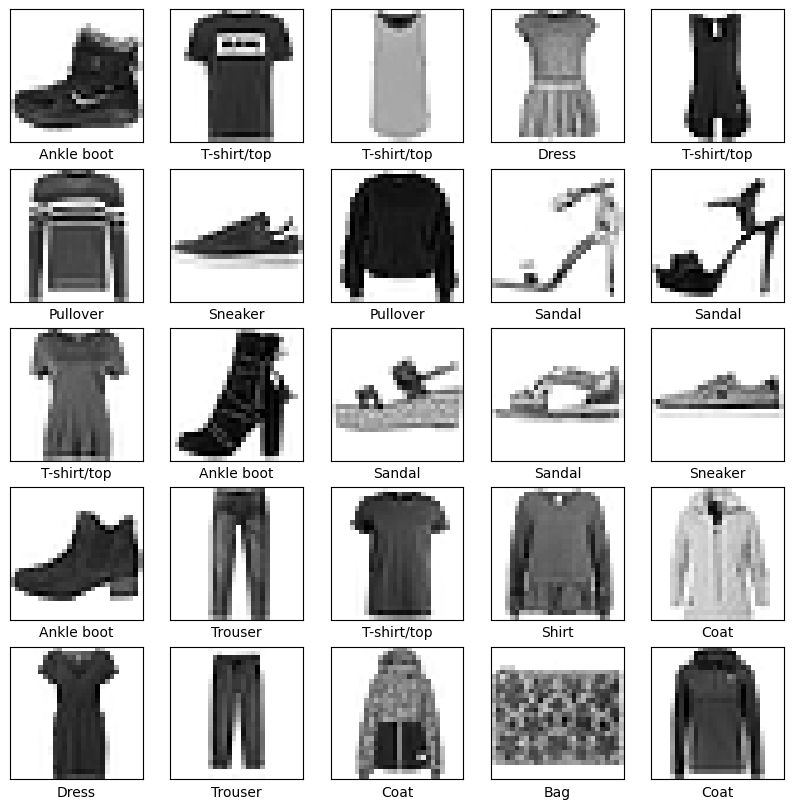

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

fashion_mnist = tf.keras.datasets.fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
X_train = X_train / 255.0
X_test = X_test / 255.0
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.show()

## Building the CNN model

The CNN architecture we propose to use is composed of one convolutional layer and one dense layer for classification. 

The convolutional layer will apply 32 small filters to the input image, followed by a max-pooling layer. We will add a dropout layer (https://keras.io/api/layers/regularization_layers/dropout/) to fight overfitting and to force the model to learn multiple representations of the same data by randomly disabling neurons in the learning phase.

The dense layer will have 128 neurons and a ReLU activation function. The output layer will have 10 neurons, one for each class, and a softmax activation function. 

In [2]:
model = tf.keras.models.Sequential()

# 1. Convolutional+Maxpooling+Dropout layer
model.add(
    tf.keras.layers.Conv2D(
        filters=32, # 32 filters to learn
        kernel_size=(3, 3), # filters of size 3x3
        strides=(1, 1), # no strides (default)
        padding='valid', # no padding (default)
        activation='relu', 
        input_shape=(28, 28, 1) # The expected input shape for this layer
    )
) 
# Maxpooling will reduce the number of parameters to learn, which shortens training time.
model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(tf.keras.layers.Conv2D(64, (3, 3), activation='relu'))
model.add(tf.keras.layers.MaxPool2D(pool_size=(2, 2)))

# 2. Dense layer
# Output from previous layer is a 3D tensor, that must be flattened to a 1D 
# vector before beiung fed to the Dense Layers.
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(128,activation='relu'))
model.add(tf.keras.layers.Dense(10,activation='softmax'))

# 3. Build the model
model.compile(optimizer='Adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Visualizing the model
It is usually important to check the main characteristics of the model before training it. The `summary` method of the model object provides a summary of the model's structure and the `plot_model` function from the `keras.utils` module can be used to visualize the model's structure.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

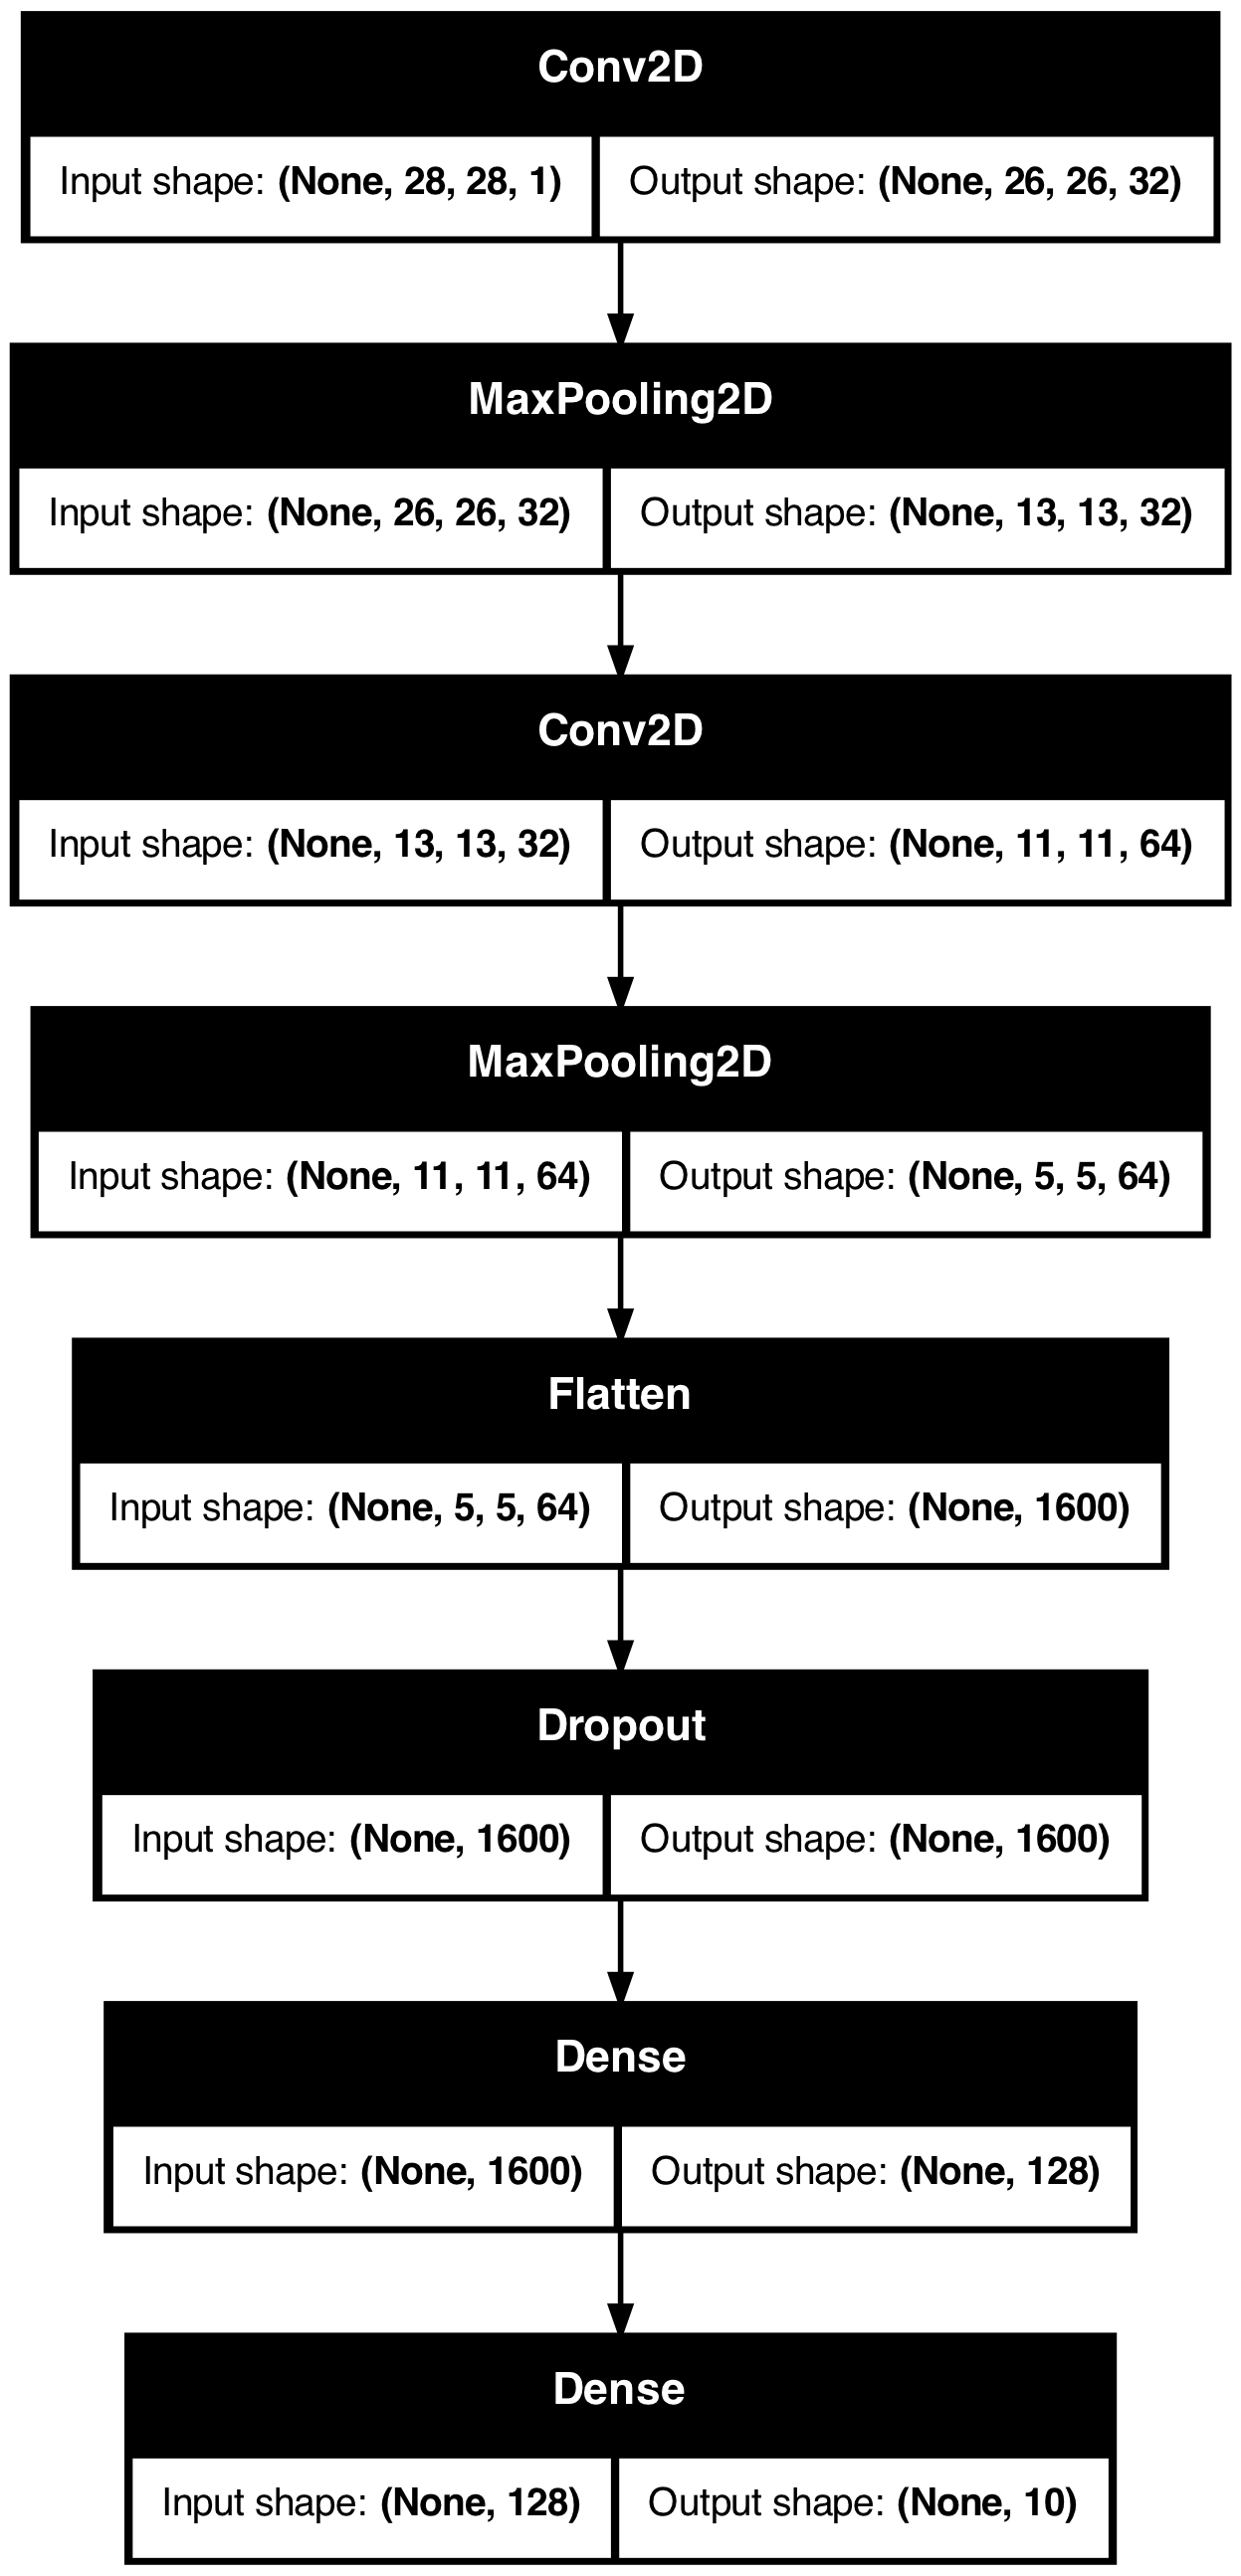

In [3]:
model.summary()
tf.keras.utils.plot_model(model, to_file='model.png', show_shapes=True)

## Training the model

The model is trained using the `fit` method of the model object. The `fit` method requires the training data, the number of epochs, and the batch size. The `validation_data` parameter can be used to provide a validation set to monitor the model's performance during training.

In [ ]:
import numpy as np

# Add an empty color dimension as the Convolutional net is expecting this
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

# Train the CNN on the training data
callbacks = [tf.keras.callbacks.ModelCheckpoint("../models/ps4_firstCNN.keras", save_best_only=True)] 
logs = model.fit(X_train, y_train, batch_size=256, epochs=20, validation_split=0.2, callbacks=callbacks) 

Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.6352 - loss: 1.0175 - val_accuracy: 0.8393 - val_loss: 0.4587
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.8251 - loss: 0.4807 - val_accuracy: 0.8648 - val_loss: 0.3875
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.8475 - loss: 0.4207 - val_accuracy: 0.8692 - val_loss: 0.3630
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.8624 - loss: 0.3794 - val_accuracy: 0.8764 - val_loss: 0.3377
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.8710 - loss: 0.3584 - val_accuracy: 0.8835 - val_loss: 0.3247
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8777 - loss: 0.3344 - val_accuracy: 0.8892 - val_loss: 0.3027
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8816 - loss: 0.3161 - val_accuracy: 0.8964 - val_loss: 0.2844
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8897 - loss: 0.3000 - val_accu

## Analysis of the result

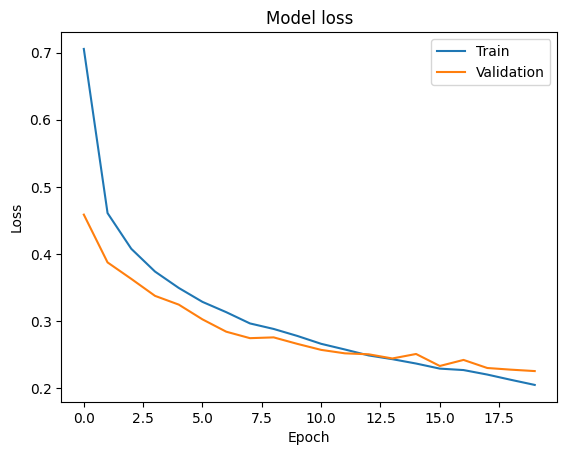

The best model have been obtained at epoch 19 with a loss equal to 0.2257360816001892


In [5]:
plt.plot(logs.history['loss']) 
plt.plot(logs.history['val_loss']) 
plt.title('Model loss') 
plt.ylabel('Loss') 
plt.xlabel('Epoch') 
plt.legend(['Train', 'Validation'], loc='upper right') 
plt.show()

best_epoch = np.argmin(logs.history['val_loss'])
best_val_loss = logs.history['val_loss'][best_epoch]
print(f"The best model have been obtained at epoch {best_epoch} with a loss equal to {best_val_loss}")

## Evaluate the performances

In [ ]:
dnn_model = tf.keras.models.load_model("../models/ps4_firstNN.keras")
test_loss, test_acc = dnn_model.evaluate(X_test, y_test, verbose=2)
print('DNN - Test loss:', test_loss)
print('DNN - Test accuracy:', test_acc)

cnn_model = tf.keras.models.load_model("../models/ps4_firstCNN.keras")
test_loss, test_acc = cnn_model.evaluate(X_test, y_test, verbose=2)
print('CNN - Test loss:', test_loss)
print('CNN - Test accuracy:', test_acc)

313/313 - 0s - 755us/step - accuracy: 0.8837 - loss: 0.3433
DNN - Test loss: 0.34331855177879333
DNN - Test accuracy: 0.8837000131607056
313/313 - 1s - 3ms/step - accuracy: 0.9116 - loss: 0.2373
CNN - Test loss: 0.23731203377246857
CNN - Test accuracy: 0.9115999937057495


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Predictions (probabilities) of the first image: [3.8207528e-08 9.0432506e-10 1.3132116e-07 9.5143108e-08 6.1532877e-09
 8.3188992e-04 1.3865279e-07 1.7936515e-03 5.3264689e-06 9.9736869e-01]
The class predicted is 9
The true class is 9


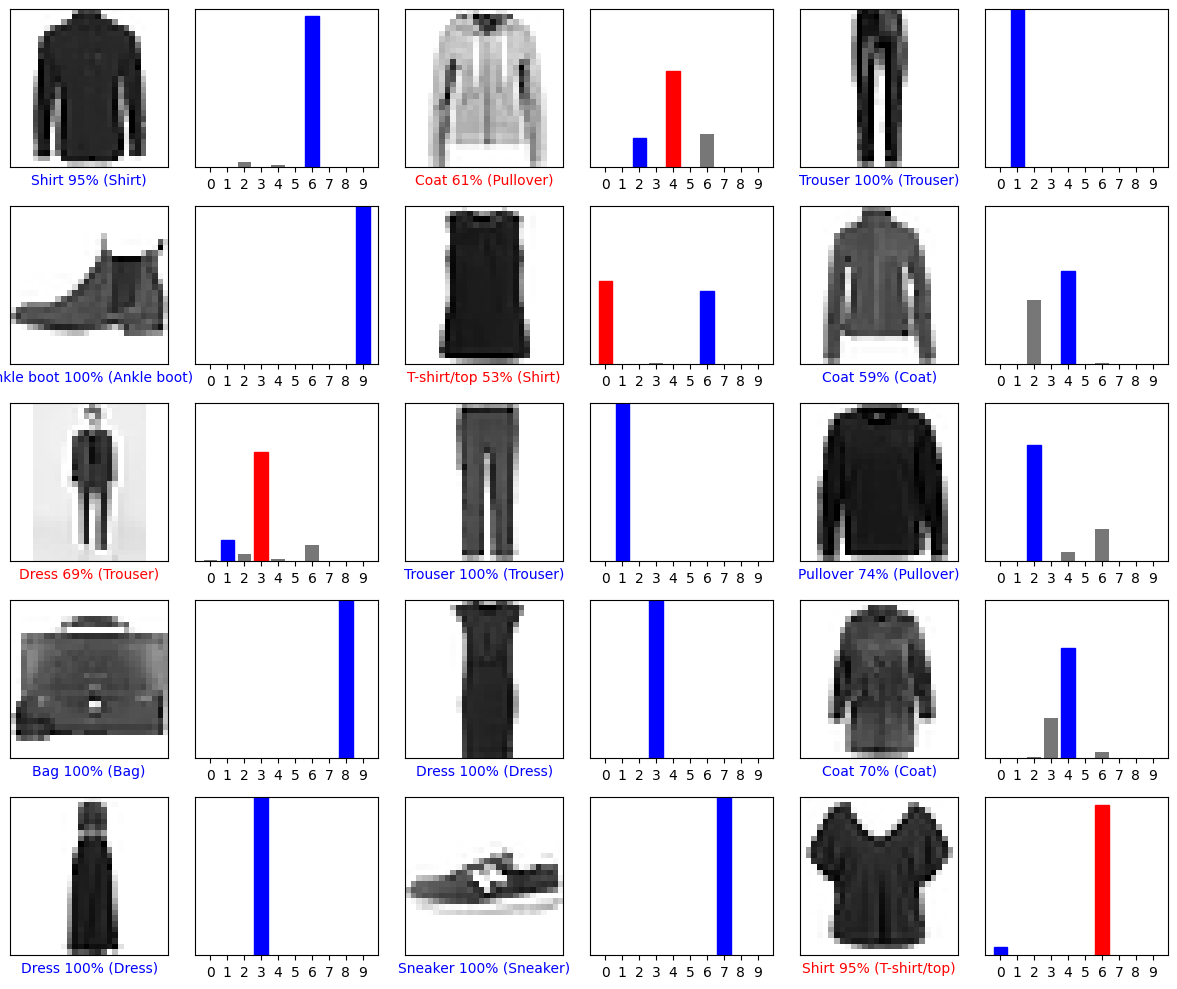

In [7]:
def plot_image(i, predictions_array, true_label, img):
    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img, cmap=plt.cm.binary)
    predicted_label = np.argmax(predictions_array)
    if predicted_label == true_label:
        color = 'blue'
    else:
        color = 'red'
    plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label], 100*np.max(predictions_array), class_names[true_label]), color=color)

def plot_value_array(i, predictions_array, true_label):
    true_label = true_label[i]
    plt.grid(False)
    plt.xticks(range(10))
    plt.yticks([])
    thisplot = plt.bar(range(10), predictions_array, color="#777777")
    plt.ylim([0, 1])
    predicted_label = np.argmax(predictions_array)
    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('blue')

predictions = model.predict(X_test)
print(f"Predictions (probabilities) of the first image: {predictions[0]}")
print(f"The class predicted is {np.argmax(predictions[0])}")
print(f"The true class is {y_test[0]}")

# Plot the first X test images, their predicted labels, and the true labels.
# Color correct predictions in blue and incorrect predictions in red.
num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
    r = np.random.randint(0, X_test.shape[0])
    plt.subplot(num_rows, 2*num_cols, 2*i+1)
    plot_image(r, predictions[r], y_test, X_test)
    plt.subplot(num_rows, 2*num_cols, 2*i+2)
    plot_value_array(r, predictions[r], y_test)
plt.tight_layout()
plt.show()